In [1]:
import numpy as np
import pandas as pd
from scipy.linalg import svd
import matplotlib.pyplot as plt
import time
import os

from sklearn.preprocessing import StandardScaler

from KRR_utils import *
from nystrom_functions import *

# Investigation of the singular values of K matrix

First, we look at the singular values of $K$ when using the real dataset Superconductivity and a linear kernel

In [2]:
os.makedirs("Results", exist_ok=True)

df = pd.read_csv("../Data/train.csv")

X = df.iloc[:, :-1].to_numpy(dtype=float)
y = df.iloc[:, -1].to_numpy(dtype=float)

print(X.shape)
print(y.shape)

(21263, 81)
(21263,)


In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
n_all = X_scaled.shape[0]
entries = n_all*n_all
memory_gb = entries*8/(1024**3)

print("full dataset n =", n_all)
print("full K entries =", entries)
print("full K memory in GB =", memory_gb)

full dataset n = 21263
full K entries = 452115169
full K memory in GB = 3.3685205057263374


In [4]:
rng = np.random.default_rng(1)

sample_n = 3000
sample_ind = rng.choice(X_scaled.shape[0], size=sample_n, replace=False)

data = X_scaled[sample_ind]
target = y[sample_ind]

print(data.shape)
print(target.shape)

(3000, 81)
(3000,)


Linear kernel singular values:

In [5]:
kernel = linear

start = time.time()

K = make_kernel_matrix(data, kernel)
sing_valK = svd(K, compute_uv=False)

end = time.time()

print("runtime =", end-start)
print("largest singular value =", sing_valK[0])
print("smallest singular value =", sing_valK[-1])

runtime = 4.205694198608398
largest singular value = 95446.87154849073
smallest singular value = 3.288694106103953e-31


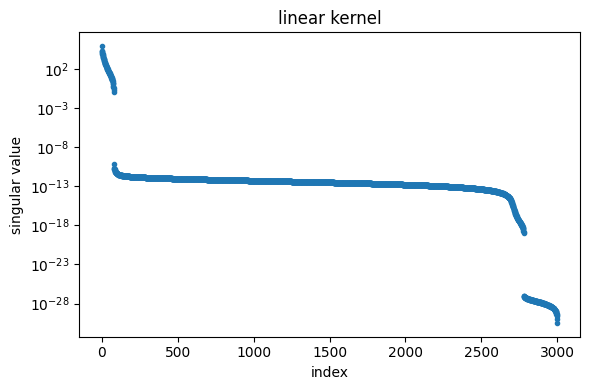

In [6]:
plt.figure(figsize=(6,4))
plt.semilogy(sing_valK, ".")
plt.xlabel("index")
plt.ylabel("singular value")
plt.title("linear kernel")
plt.tight_layout()
plt.savefig("../Results/sing_vals_linear_kernel.pdf")
plt.show()

Gaussian RBF kernel singular values:

In [7]:
gamma = 1/data.shape[1]

def rbf_kernel(A, B):
    K = rbf(A, B, gamma=gamma)
    return K

kernel = rbf_kernel

start = time.time()

K = make_kernel_matrix(data, kernel)
sing_valK = svd(K, compute_uv=False)

end = time.time()

print("gamma =", gamma)
print("runtime =", end-start)
print("largest singular value =", sing_valK[0])
print("smallest singular value =", sing_valK[-1])

gamma = 0.012345679012345678
runtime = 3.9711320400238037
largest singular value = 1091.9104857744287
smallest singular value = 1.7641943153034874e-21


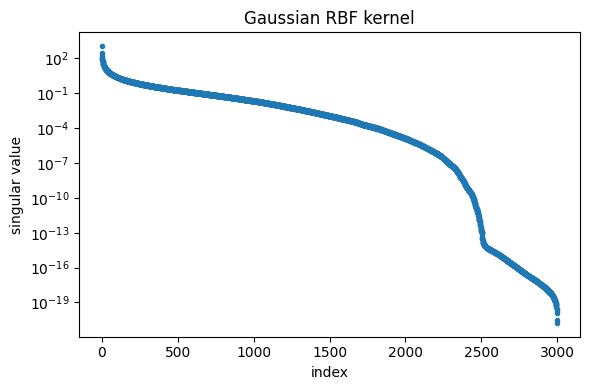

In [8]:
plt.figure(figsize=(6,4))
plt.semilogy(sing_valK, ".")
plt.xlabel("index")
plt.ylabel("singular value")
plt.title("Gaussian RBF kernel")
plt.tight_layout()
plt.savefig("../Results/sing_vals_rbf_kernel.pdf")
plt.show()